# Predicting the next byte with a residual SNN

We'll train a small language model on part of *Alice's Adventures in Wonderland*, predicting the next byte at every timestep. Unlike the image and audio classifiers, this model makes a prediction immediately rather than collecting a final output. Its residual neuron layers can add earlier context to the current byte, and we'll update the weights after each prediction while retaining the numerical memory.

This is a short experiment in model construction and online training, rather than an attempt to produce a state-of-the-art language model. We'll inspect decays, follow the gradient boundary, generate a sample and save the memory of an unfinished stream.

After installing the repository, use `pip install -r examples/alice_language_model/requirements.txt` and open `examples/alice_language_model/tutorial.ipynb`. The neighboring `main.py` contains the finished automatic program. Our default corpus comes from [Project Gutenberg](https://www.gutenberg.org/ebooks/11), whose complete source and licence remain in the shared data cache.

Source on GitHub: [notebook](https://github.com/Yegor-men/tracetorch/blob/main/examples/alice_language_model/tutorial.ipynb) and [complete program](https://github.com/Yegor-men/tracetorch/blob/main/examples/alice_language_model/main.py).

In [1]:
from pathlib import Path
from time import perf_counter
from urllib.request import urlopen

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
import tracetorch as tt

# Keep saved figures readable regardless of the notebook editor's theme.
plt.style.use("default")
torch.manual_seed(0)
torch.set_num_threads(2)
device = "cpu"
DATA_ROOT = Path("../data")
checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(exist_ok=True)

CORPUS_URL = "https://www.gutenberg.org/ebooks/11.txt.utf-8"

## 1. Inspecting the bytes

We'll use a vocabulary of all 256 byte values. Since UTF-8 can represent one written character with several bytes, this is a byte prediction task rather than exactly one prediction per character. That keeps the vocabulary fixed without needing a tokenizer or a learned text encoding.

The loader selects up to 40,000 bytes and excludes the default Gutenberg header and footer from the modelling text, while preserving the original download. When running this notebook from `examples/alice_language_model`, `../data` points to the shared cache and the local `checkpoints` folder will hold our saves.

In [2]:
def load_corpus(corpus_path, max_bytes):
    if corpus_path is None:
        corpus_path = DATA_ROOT / "alice.txt"
        if not corpus_path.exists():
            corpus_path.parent.mkdir(parents=True, exist_ok=True)
            with urlopen(CORPUS_URL, timeout=60) as response:
                content = response.read()
            corpus_path.write_bytes(content)
        content = corpus_path.read_bytes()
        # Keep Gutenberg's source file intact; train on the book, not its licence header/footer.
        start_marker = b"*** START OF THE PROJECT GUTENBERG EBOOK"
        end_marker = b"*** END OF THE PROJECT GUTENBERG EBOOK"
        start = content.find(start_marker)
        end = content.find(end_marker)
        if start >= 0:
            content = content[content.find(b"\n", start) + 1:end if end >= 0 else None]
    else:
        # Read only the requested budget when using a larger local corpus.
        with corpus_path.open("rb") as source:
            content = source.read(max_bytes if max_bytes else -1)
    if max_bytes:
        content = content[:max_bytes]
    return torch.tensor(list(content), dtype=torch.long)

In [3]:
tokens = load_corpus(None, 40000)
print("Selected bytes:", tokens.numel())
print(bytes(tokens[:160].tolist()).decode("utf-8", errors="replace"))
print("First byte indices:", tokens[:16].tolist())

Selected bytes: 40000

[Illustration]




Alice’s Adventures in Wonderland

by Lewis Carroll

THE MILLENNIUM FULCRUM EDITION 3.0

Contents

 CHAPTER I.     Down the R
First byte indices: [13, 10, 91, 73, 108, 108, 117, 115, 116, 114, 97, 116, 105, 111, 110, 93]


The decoded sample lets us check that we're reading book content, while the printed indices show what the network will actually receive. If you'd like to use another uncompressed corpus, pass its path in place of `None`; the automatic program exposes this as `--corpus /path/to/enwik8 --max-bytes 100000`.

## 2. Keeping text streams continuous

We'll reserve the final 10% of the selected text for validation, so training and validation don't share targets. Within each region, we'll divide the bytes into 32 contiguous streams, one for each batch position. This arrangement lets a hidden state keep following the same passage as we advance one byte at a time.

In [4]:
def make_streams(tokens, batch_size):
    """Split contiguous text into fixed lanes, returning [T, B] byte indices."""
    steps = tokens.numel() // batch_size
    if steps < 2:
        raise ValueError("Corpus split must contain at least two bytes per stream lane")
    return tokens[:steps * batch_size].view(batch_size, steps).T.contiguous()

In [5]:
small = make_streams(torch.tensor(list(b"abcdefghijkl")), 2)
print(small)
for column in range(2):
    print("Lane", column, bytes(small[:, column].tolist()).decode())

split = int(0.9 * tokens.numel())
train = make_streams(tokens[:split], 32).to(device)
validation = make_streams(tokens[split:], 32).to(device)
print("Training:", train.shape, "Validation:", validation.shape)

tensor([[ 97, 103],
        [ 98, 104],
        [ 99, 105],
        [100, 106],
        [101, 107],
        [102, 108]])
Lane 0 abcdef
Lane 1 ghijkl
Training: torch.Size([1125, 32]) Validation: torch.Size([125, 32])


In the small example, the two lanes read `abcdef` and `ghijkl`. Each row supplies one byte per lane, and the target is the next byte in that same lane. We don't predict across a lane boundary; any trailing bytes that can't fill equal lanes are discarded.

That continuity is why we won't shuffle the rows while retaining states. A hidden vector built from one passage would give the wrong context to an unrelated passage, even if the tensor shapes happened to match.

## 3. Adding context to the current byte

An embedding turns each byte index into 64 learned features. A direct linear projection from those features could already learn a first-order Markov predictor: the next-byte distribution would depend only on the current byte. We'll keep that immediate path, then give the model an opportunity to add information from earlier bytes through two residual blocks:

$$h_t^{(\ell+1)}=h_t^{(\ell)}
 +W_2^{(\ell)}s_t^{(\ell)}(W_1^{(\ell)}h_t^{(\ell)}).$$

Here $\ell$ identifies the block and $s_t$ is its neuron output; the projections also have biases. Each block uses LIB with smooth firing,

$$m_t=\beta(m_{t-1}-\theta s_{t-1})+u_t,\qquad
s_t=\sigma(4(m_t-\theta)),$$

where $u_t$ is the first projection's output. The membrane holds history, while the second projection decides how its firing changes the current features. Both projections start with small, nonzero weights so the block initially stays close to the identity while allowing both projections to learn.

We'll initialize each neuron's decay directly with `torch.rand(width)`. There is no synaptic filter in this model: we use the byte's learned features directly as the membrane input. There is also no final LI; a single linear readout maps the current residual features to 256 next-byte scores. These are design choices for this experiment, rather than restrictions on what recurrent architectures can model text.

In [6]:
class ResidualBlock(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.lin1 = nn.Linear(width, width)
        self.neuron = tt.snn.LIB(
            width, beta=torch.rand(width), spike_fn=tt.snn.spike_fn.smooth,
        )
        self.lin2 = nn.Linear(width, width)
        # Small nonzero projections start near the identity and let both projections learn.
        for projection in (self.lin1, self.lin2):
            nn.init.normal_(projection.weight, std=0.01)
            nn.init.zeros_(projection.bias)

    def forward(self, x):
        return x + self.lin2(self.neuron(self.lin1(x)))


class ByteSNN(tt.Model):
    def __init__(self, width=64, depth=2):
        super().__init__()
        self.embedding = nn.Embedding(256, width)
        self.blocks = nn.Sequential(*(ResidualBlock(width) for _ in range(depth)))
        self.readout = nn.Linear(width, 256)

    def forward(self, byte):
        return self.readout(self.blocks(self.embedding(byte)))

Each call receives `[B]` integer byte indices and returns `[B, 256]` logits. The residual blocks add a history-dependent correction without removing the direct path from the current byte. Because their initial contribution is small, the untrained model is close to a current-byte predictor. It can learn to use context as those contributions grow; this is recurrent memory, rather than a query/key attention operation.

## 4. Exploring the random decays

A decay below 0.5 loses more than half of a passive trace in one step, so many neurons react quickly. A few decays will be near one and preserve a much longer tail. We can express that range through the same horizon used for SHD:

$$H=\frac{1}{1-\beta}.$$

Uniform decays give a range of horizons without asking us to choose a maximum passage length. For an ideal continuous uniform draw, $P(H>h)=1/h$ for $h\geq1$. Among $N$ neurons, we therefore expect $N/h$ to start with horizons longer than $h$ steps. Increasing the width naturally adds opportunities for longer traces alongside the quick ones.

There is also a useful relation for the largest decay $M=\max_i\beta_i$:

$$P(M\leq m)=m^N,\qquad \mathbb E[M]=\frac{N}{N+1},
\qquad H(\mathbb E[M])=N+1.$$

That last expression converts the expected largest **decay** into a horizon. It isn't the expected largest horizon: taking a reciprocal changes the expectation, and the ideal continuous distribution has no finite mean maximum horizon. A finite floating-point draw is bounded and varies from run to run. We don't need an exact longest timescale to use this initialization.

Let's inspect the actual decays from one block and plot a few passive traces. Firing, reset and learned projections make the trained memory more involved than these curves, but the plot shows what the decay itself retains.

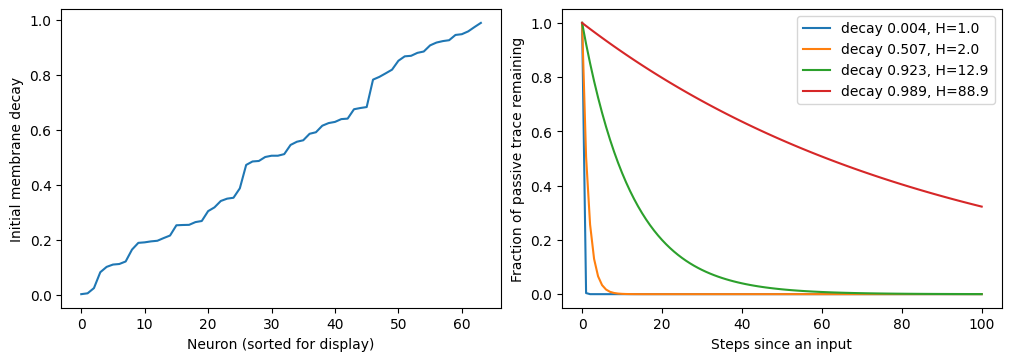

Initial residual change relative to embedding: 0.24%


In [7]:
torch.manual_seed(0)
initial = ByteSNN(width=64, depth=2).to(device)
decays = initial.blocks[0].neuron.beta.detach().cpu().sort().values
steps = torch.arange(101)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
axes[0].plot(decays)
axes[0].set_xlabel("Neuron (sorted for display)")
axes[0].set_ylabel("Initial membrane decay")
for index in (0, 31, 57, 63):
    beta = decays[index].item()
    axes[1].plot(steps, beta ** steps, label=f"decay {beta:.3f}, H={1 / (1 - beta):.1f}")
axes[1].set_xlabel("Steps since an input")
axes[1].set_ylabel("Fraction of passive trace remaining")
axes[1].legend()
plt.show()

initial.eval()
with torch.no_grad():
    features = initial.embedding(torch.arange(256, device=device))
    adjusted = initial.blocks(features)
    relative_change = (adjusted - features).norm() / features.norm()
print(f"Initial residual change relative to embedding: {relative_change:.2%}")
initial.reset_states()

Most passive traces fade quickly, while a few retain a visible contribution much later. The printed residual change is small at initialization, which checks the intended direct path through the blocks. After training, the same architecture can make a larger history-dependent correction.

## 5. Updating after every byte

At timestep $t$, the target is the next byte $x_{t+1}$. We average its cross-entropy over the $B$ stream lanes:

$$\mathcal L_t=-\frac{1}{B}\sum_{b=1}^{B}
\log p_{\theta_t}(x_{t+1,b}\mid x_{\leq t,b}).$$

The subscript on $\theta_t$ reminds us that the weights can change after each timestep. We'll calculate this loss, call backward, update the parameters and then call `model.detach_states()` before advancing the stream.

Calculating a loss doesn't clear the autograd graph. Backward normally frees saved intermediates, but the state's tensor still points to its preceding calculations until we detach it. `optimizer.zero_grad()` clears accumulated parameter gradients; it doesn't detach memory either. We need each operation here for a different reason.

In [8]:
def run_epoch(model, streams, optimizer=None):
    training = optimizer is not None
    model.train(training)
    model.reset_states()
    total_loss = total_bytes = 0
    with torch.set_grad_enabled(training):
        for timestep in range(streams.shape[0] - 1):
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(streams[timestep])
            targets = streams[timestep + 1]
            loss = F.cross_entropy(logits, targets)
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                # Preserve stream memory without backpropagating into earlier updates.
                model.detach_states()
            total_loss += loss.item() * targets.numel()
            total_bytes += targets.numel()
    model.reset_states()
    return total_loss / total_bytes

The target `streams[timestep + 1]` is the next byte in each lane. Every update averages the loss over those lanes, then backpropagates, clips the parameter gradients, changes the weights and detaches the states.

We reset at the start of a corpus pass and before validation because those are independent passes through text. Within training, detaching after every update preserves the membrane values while cutting their connection to earlier computations. Resetting there would instead erase the context.

This is **one-step truncated backpropagation through time**. The current loss can train how the current update uses the stored values, but it cannot send credit back to the earlier computations that created them. More numerical memory doesn't by itself give a longer training gradient. Processing several timesteps before backward and detach would extend that gradient interval; we'll keep the one-step case visible here.

In [9]:
torch.manual_seed(0)
model = ByteSNN(width=64, depth=2).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3)
baseline = run_epoch(model, validation)
history = {"train_loss": [], "validation_loss": [baseline]}
print(f"Before training: validation loss={baseline:.3f} nats/byte")
started = perf_counter()
for epoch in range(1, 4):
    train_loss = run_epoch(model, train, optimizer)
    validation_loss = run_epoch(model, validation)
    history["train_loss"].append(train_loss)
    history["validation_loss"].append(validation_loss)
    print(f"Epoch {epoch}: train={train_loss:.3f}, validation={validation_loss:.3f}")
print(f"Training and evaluation: {perf_counter() - started:.1f}s")

Before training: validation loss=5.654 nats/byte
Epoch 1: train=2.467, validation=2.232
Epoch 2: train=2.169, validation=2.140
Epoch 3: train=2.080, validation=2.076
Training and evaluation: 2.4s


## 6. Reading the learning curve

Let's plot the loss from training and validation. We're measuring nats per byte, which uses natural logarithms: a lower value means the model assigns more probability to the correct next byte. For comparison, a uniform distribution over 256 bytes has loss $\log 256\approx5.545$.

In [10]:
def plot_history(history):
    fig, axis = plt.subplots(figsize=(7, 3.5), layout="constrained")
    axis.plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], label="Training")
    axis.plot(history["validation_loss"], label="Validation")
    axis.set_xlabel("Epoch (0 = before training)")
    axis.set_ylabel("Loss (nats per byte)")
    axis.legend()
    return fig

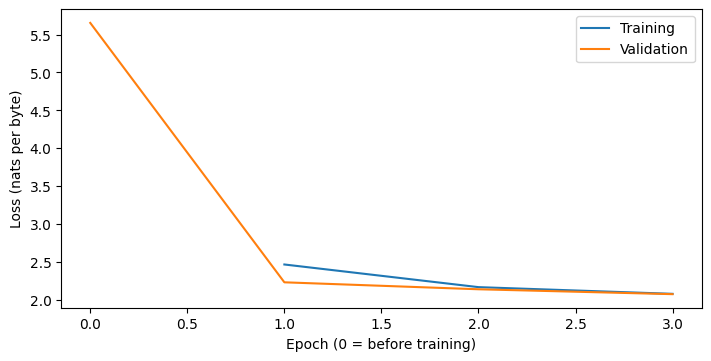

In [11]:
plot_history(history)
plt.show()

### Checking that the same byte can use different histories

A current-byte predictor would return the same distribution whenever the current byte is the same. Let's instead give the trained model two prefixes that both end in a space, then compare their next-byte distributions. We'll reset between prefixes so each has its own history. This inspects the effect of recurrent context; it doesn't establish that one prediction is better than another.

In [12]:
distributions = []
model.eval()
with torch.no_grad():
    for prefix in (b"Alice ", b"the "):
        model.reset_states()
        for byte in prefix:
            logits = model(torch.tensor([byte], device=device))
        probabilities = logits.softmax(-1).squeeze(0)
        distributions.append(probabilities)
        next_bytes = probabilities.topk(5).indices.tolist()
        print(prefix, "most likely next bytes:", [bytes([value]) for value in next_bytes])
difference = (distributions[0] - distributions[1]).abs().sum() / 2
print(f"Total variation between distributions: {difference.item():.3f}")
model.reset_states()

b'Alice ' most likely next bytes: [b't', b'h', b'a', b'w', b'o']
b'the ' most likely next bytes: [b'w', b't', b'a', b's', b'h']
Total variation between distributions: 0.230


The reference validation loss falls from about 5.654 to 2.076 over three epochs, moving well below the uniform starting point. Validation uses a different text region and starts from reset states, so it can't inherit the training passage's hidden memory.

## 7. Generating a text sample

We can now consume a prompt, sample a byte from the predicted distribution, and feed that byte back into the model. Repeating this extends the prompt one byte at a time. We'll divide the logits by a temperature before sampling; a lower temperature concentrates probability on the model's more likely choices.

In [13]:
def generate(model, prompt, length, device, temperature=0.8):
    model.eval()
    model.reset_states()
    result = bytearray(prompt.encode("utf-8"))
    if not result:
        raise ValueError("Generation prompt must contain at least one byte")
    with torch.no_grad():
        for byte in result:
            logits = model(torch.tensor([byte], device=device))
        for _ in range(length):
            probabilities = (logits / temperature).softmax(-1)
            next_byte = torch.multinomial(probabilities, 1).squeeze(-1)
            result.append(next_byte.item())
            logits = model(next_byte)
    model.reset_states()
    return result.decode("utf-8", errors="replace")

In [14]:
torch.manual_seed(0)
print(generate(model, "Alice ", 160, device))

Alice soupping the sain onk and the sou inglste
det was land and whever supasnd in the doo te and beden—and an you thead ou swawaik bupoon y a she was seas id yoor


The sample contains fragments of plausible spelling alongside misspellings and broken sentences, which is a reasonable result for this small training budget. It gives us another view of the learned predictions rather than a guarantee of language understanding. We also allow decoding to replace invalid UTF-8 sequences because independently sampled bytes don't always form valid characters.

Try keeping the prompt and trained weights fixed while changing temperature from 0.8 to 0.5. Resetting the random seed before each sample makes the experiment repeatable, while resetting the model's states ensures each sample begins from that prompt rather than the previous generated passage.

## 8. Saving weights and optimizer state

At an epoch boundary, the next corpus pass begins from reset states, so we can save the learned model without a hidden-state snapshot. We'll put its weights, optimizer and dimensions in `checkpoints/model.pt`, which gives us what we need to reconstruct it for another pass.

In [15]:
checkpoint = checkpoint_dir / "model.pt"
torch.save({"weights": model.state_dict(), "optimizer": optimizer.state_dict(),
            "width": 64, "depth": 2, "completed_epochs": 3}, checkpoint)
print(checkpoint)

checkpoints/model.pt


## 9. Saving memory in the middle of a stream

Pausing inside a passage is a different case. The weights tell us how the model behaves, but the hidden state tells us which prefix it has already processed. We'll also need to know where the next input begins, so we'll save the cursor alongside a detached copy of the states in `checkpoints/states.pt`.

Let's process a prefix, save that snapshot, and then calculate all the remaining outputs without interruption. Those outputs will give us a reference for the restored run.

In [16]:
model.eval()
model.reset_states()
sequence = torch.tensor(list(b"Alice was beginning to get very tired."), device=device).unsqueeze(1)
cursor = 16
with torch.no_grad():
    for byte in sequence[:cursor]:
        model(byte)
    torch.save({"states": model.save_states(), "cursor": cursor, "sequence": sequence.cpu()}, checkpoint_dir / "states.pt")
    expected = torch.stack([model(byte) for byte in sequence[cursor:]])

Now we'll construct a fresh model, load the weights from `model.pt`, and load the sequence memory from `states.pt`. Strict state loading checks that the declared state names match the snapshot. We can then start at the saved cursor without resetting, since a reset would discard the prefix memory we just restored.

In [17]:
saved_weights = torch.load(checkpoint, map_location=device, weights_only=True)
restored = ByteSNN(saved_weights["width"], saved_weights["depth"]).to(device)
restored.load_state_dict(saved_weights["weights"])
saved_stream = torch.load(checkpoint_dir / "states.pt", map_location=device, weights_only=True)
restored.load_states(saved_stream["states"])
restored.eval()
with torch.no_grad():
    actual = torch.stack([restored(byte) for byte in saved_stream["sequence"][saved_stream["cursor"]:]])
print("Maximum suffix score difference:", (actual - expected).abs().max().item())
torch.testing.assert_close(actual, expected)

Maximum suffix score difference: 0.0


Every remaining output agrees with the uninterrupted run, which checks that the restored memory and input position describe the same computation. Reproducing randomly sampled text would require an additional detail—the random generator state—because sampling makes choices beyond the deterministic model outputs we're comparing here.

For multiple lanes, each restored batch position also needs to continue its original passage. The state tensor, cursor and lane arrangement together describe where a stream left off.

The reference training and evaluation take roughly three seconds on CPU, excluding download. The complete program is `python examples/alice_language_model/main.py --device cpu`; it generates a sample, saves `model.pt` and `states.pt` in the example's `checkpoints` folder, and verifies continuation.